# <a id='toc1_'></a>[Floresta Aleatória](#toc0_)

**Sumário**<a id='toc0_'></a>    
- [Floresta Aleatória](#toc1_)    
  - [Introdução](#toc1_1_)    
  - [Desenvolvimento](#toc1_2_)    
    - [Separação treino e teste - validação cruzada](#toc1_2_1_)    
    - [Aplicando a Árvore de Decisão](#toc1_2_2_)    
    - [Otimização de hiperparâmetros](#toc1_2_3_)    
    - [Analisando os resultados](#toc1_2_4_)    
  - [Conclusão](#toc1_3_)    
  - [Referências](#toc1_4_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

## <a id='toc1_1_'></a>[Introdução](#toc0_)

Nesse notebook, iremos implementar o modelo de Floresta Aleatória ao nosso dataset. Depois de implementá-lo, também vamos otimizar seus hiperparâmetros e comparar os resultados obtidos com outros modelos.

## <a id='toc1_2_'></a>[Desenvolvimento](#toc0_)

Vamos iniciar coletando e tratando os dados que iremos utilizar, como feito no notebook [01.A - Baseline](01.A%20-%20Baseline.ipynb). Dessa vez, como vamos realizar a otimização, vamos dividir nosso conjunto em dados de treino e dados de teste.

In [1]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

ATTRIBUTES = [
    "epicenter_distance",
    "geodesic_distance",
    "azimuth_degree",
    "magnitude",
    "magnitude_type",
    "depth",
    "first_arrival_time_delta",
    "arrival_time_delta",
    "land_fraction",
    "origin_plate"
]

TARGET = [
    "amplitude_factor_log10"
]

df_earthquakes = pd.read_csv("../00 - Coleta e Tratamento de Dados/Data/earthquake_dataset_treated.csv")

X = df_earthquakes.reindex(ATTRIBUTES, axis=1)
y = df_earthquakes.reindex(TARGET, axis=1)

CATEGORICAL_ATTRIBUTES = ["magnitude_type", "origin_plate"]
NUMERICAL_ATTRIBUTES = [
    column for column in X.columns
    if column not in CATEGORICAL_ATTRIBUTES
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            CATEGORICAL_ATTRIBUTES
        ),
        (
            "numerical",
            "passthrough",
            NUMERICAL_ATTRIBUTES
        )
    ]
)

### <a id='toc1_2_1_'></a>[Separação treino e teste - validação cruzada](#toc0_)

Para dividir os dados de treino e teste, de forma à estimar as métricas dos modelos induzidos de uma forma mais confiável, iremos utilizar a técnica de **Validação cruzada**. Mais especificamente, aplicaremos o método $k$-fold, a partir da biblioteca `scikit-learn`.

In [2]:
from sklearn.model_selection import KFold

NUM_FOLDS = 10
RANDOM_STATE = 424242

TEST_SIZE = 0.1

df_earthquakes = df_earthquakes.reindex(ATTRIBUTES + TARGET, axis=1)

y_bins = pd.qcut(
    y.values.ravel(),
    q=5,
    labels=False,
    duplicates="drop"
)

idx = df_earthquakes.index
train_idx, test_idx = train_test_split(idx, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_bins)

df_train = df_earthquakes.iloc[train_idx]
df_test = df_earthquakes.iloc[test_idx]

X_train = df_train.reindex(ATTRIBUTES, axis=1)
y_train = df_train.reindex(TARGET, axis=1)

X_test = df_test.reindex(ATTRIBUTES, axis=1)
y_test = df_test.reindex(TARGET, axis=1)

kf = KFold(NUM_FOLDS, shuffle=True, random_state=RANDOM_STATE)

### <a id='toc1_2_2_'></a>[Aplicando a Árvore de Decisão](#toc0_)

Vamos utilizar o `RandomForestRegressor` do **scikit-learn** para induzir nosso modelo, de acordo com a referência [2].

A métrica que utilizaremos de referência será o RMSE, que é a raiz do erro quadrático médio das previsões do nosso modelo.

As métricas foram:
 0 - 0.4852701250212008
 1 - 0.2474761861550611
 2 - 0.36815032119458163
 3 - 0.641587567571392
 4 - 0.33586731695880573
 5 - 0.16748257801289526
 6 - 0.3580595040853043
 7 - 0.5290374061084903
 8 - 0.46307632462584475
 9 - 0.6092096429706801


A média das métricas é de: 0.4205216972704256


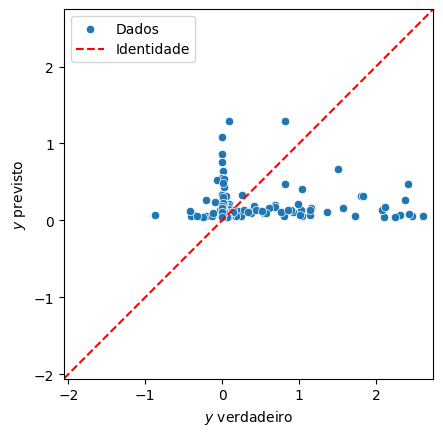

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error
import seaborn as sns
import numpy as np

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(max_leaf_nodes=6))
    ]
)

def test_kf(model, X=X, y=y, kf=kf, plot=True):
    metrics = []
    true_y = []
    pred_y = []

    for train_idx, test_idx in kf.split(X):

        X_train_, X_test_ = X.iloc[train_idx], X.iloc[test_idx]
        y_train_, y_test_ = y.iloc[train_idx], y.iloc[test_idx]

        model.fit(X_train_, y_train_.values.ravel())

        true_y_ = y_test_
        pred_y_ = model.predict(X_test_)
        
        true_y.append(true_y_)
        pred_y.append(pred_y_)

        RMSE = root_mean_squared_error(true_y_, pred_y_)

        metrics.append(RMSE)

    if plot:
        print("As métricas foram:\n", *[f"{i} - {metric}\n" for i, metric in enumerate(metrics)])
        print()
        print("A média das métricas é de:", np.mean(metrics))

        true_y = np.concatenate(true_y).ravel()
        pred_y = np.concatenate(pred_y).ravel()

        min_val = min(true_y.min(), pred_y.min())
        max_val = max(true_y.max(), pred_y.max())

        interval = [min_val * 0.95, max_val * 1.05]

        ax = sns.scatterplot(x=true_y, y=pred_y, label="Dados")
        ax.plot(interval, interval, "r--", label="Identidade")

        ax.set(
            xlabel="$y$ verdadeiro",
            ylabel="$y$ previsto",
            xlim=interval,
            ylim=interval,
            aspect="equal",
        )
        ax.legend();
    
    return metrics
    
rf_metrics = test_kf(rf_model)

Podemos ver que já houve uma tentativa diferente do modelo para tentar prever cada uma das ampitudes, com uma liberdade e variância maior do que a obtida utilizando a Árvore de Decisão. Entretanto, o modelo utilizado parece não ter atingido uma complexidade suficiente para descrever corretamente o padrão dos dados, praticamente se igualando ao baseline. Vamos ver como ele se comporta ao otmizar os os hiperparâmetros utilizando o optuna.

### <a id='toc1_2_3_'></a>[Otimização de hiperparâmetros](#toc0_)

Para os atributos, iremos definir as seguintes opções:

- `n_estimators`: varia de 50 a 300, definindo a quantidade de árvores utilizadas na floresta e permitindo avaliar diferentes tamanhos do conjunto de árvores.
- `max_depth`: varia de 2 a 20, permitindo controlar a profundidade máxima das árvores e, consequentemente, a complexidade dos modelos individuais.
- `min_samples_split`: varia de 2 a 20, definindo a quantidade mínima de amostras necessária para que um nó possa ser dividido e ajudando a controlar o crescimento das árvores.
- `min_samples_leaf`: varia de 1 a 10, estabelecendo a quantidade mínima de amostras que cada folha pode possuir, reduzindo o risco de que as árvores se ajustem excessivamente a poucas observações.
- `max_features`: podemos escolher entre `None`, `"sqrt"` e `"log2"`, comparando diferentes quantidades de atributos consideradas em cada divisão das árvores.

In [ ]:
def create_model_instance(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 300),
        "max_depth": trial.suggest_int("max_depth", 2, 20),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
        "max_features": trial.suggest_categorical(
            "max_features",
            [None, "sqrt", "log2"]
        ),
    }
    
    
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(**params))
    ]
    
    
    rf_model = Pipeline(steps)
    
    return rf_model

Agora, vamos definir a função objetivo, que vai medir a métrica do modelo.

In [12]:
def objective_function(trial, X, y, kf, num_folds):
    model = create_model_instance(trial)
    
    metrics = test_kf(model, X, y, kf, plot=False)
    
    return np.mean(metrics)

Então, vamos criar o objeto de estudo, que será responsável por buscar os melhores hiperparâmetros do espaço delimitado

In [13]:
from optuna import create_study, delete_study, get_all_study_summaries

STUDY_NAME = "Studies/rf_tiamat"
STORAGE = f"sqlite:///{STUDY_NAME}.db"

studies = get_all_study_summaries(storage=STORAGE)

if any(study.study_name == STUDY_NAME for study in studies):
    delete_study(
        study_name=STUDY_NAME,
        storage=STORAGE
    )

study_obj = create_study(
    direction="minimize",
    study_name=STUDY_NAME,
    storage=STORAGE,
    load_if_exists=True,
)

[I 2026-11-16 08:59:57,765] A new study created in RDB with name: Studies/rf_tiamat


Utilizando o funtools. podemos criar nossa função objetiva parcial

In [14]:
from functools import partial

partial_objective_function = partial(
    objective_function, X=X_train, y=y_train, kf=kf, num_folds=NUM_FOLDS
)

E, por fim, otimizamos o estudo a partir do método `optimize`. Vamos utilizar um número de tentativas inicial como 100.

In [15]:
N_TRIALS = 100

study_obj.optimize(partial_objective_function, n_trials=N_TRIALS)

[I 2026-11-16 09:00:29,195] Trial 0 finished with value: 0.4105600283256618 and parameters: {'n_estimators': 270, 'max_depth': 14, 'min_samples_split': 11, 'min_samples_leaf': 5, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.4105600283256618.
[I 2026-11-16 09:00:30,176] Trial 1 finished with value: 0.41118270108940347 and parameters: {'n_estimators': 96, 'max_depth': 6, 'min_samples_split': 12, 'min_samples_leaf': 5, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.4105600283256618.
[I 2026-11-16 09:00:31,684] Trial 2 finished with value: 0.40945974539515306 and parameters: {'n_estimators': 177, 'max_depth': 20, 'min_samples_split': 20, 'min_samples_leaf': 5, 'max_features': 'sqrt'}. Best is trial 2 with value: 0.40945974539515306.
[I 2026-11-16 09:00:33,922] Trial 3 finished with value: 0.4196612170376624 and parameters: {'n_estimators': 181, 'max_depth': 5, 'min_samples_split': 8, 'min_samples_leaf': 4, 'max_features': None}. Best is trial 2 with value: 0.4094597453951

### <a id='toc1_2_4_'></a>[Analisando os resultados](#toc0_)

Vamos observar os resultados do estudo

In [16]:
df = study_obj.trials_dataframe()

df

,number,value,datetime_start,datetime_complete,duration,params_max_depth,params_max_features,params_min_samples_leaf,params_min_samples_split,params_n_estimators,system_attrs_tpe:relative_params:0,state
0,0,0.410560,2026-11-16 09:00:26.673661,2026-11-16 09:00:29.167569,0 days 00:00:02.493908,14,sqrt,5,11,270,NaN,COMPLETE
1,1,0.411183,2026-11-16 09:00:29.200503,2026-11-16 09:00:30.150138,0 days 00:00:00.949635,6,sqrt,5,12,96,NaN,COMPLETE
2,2,0.409460,2026-11-16 09:00:30.184965,2026-11-16 09:00:31.662469,0 days 00:00:01.477504,20,sqrt,5,20,177,NaN,COMPLETE
3,3,0.419661,2026-11-16 09:00:31.691222,2026-11-16 09:00:33.899898,0 days 00:00:02.208676,5,None,4,8,181,NaN,COMPLETE
4,4,0.412168,2026-11-16 09:00:33.929255,2026-11-16 09:00:35.689536,0 days 00:00:01.760281,10,log2,2,10,216,NaN,COMPLETE
...,...,...,...,...,...,...,...,...,...,...,...,...
95,95,0.409317,2026-11-16 09:03:31.940705,2026-11-16 09:03:34.474804,0 days 00:00:02.534099,12,log2,8,11,200,"{""max_depth"": 12, ""max_features"": ""log2"", ""min...",COMPLETE
96,96,0.410877,2026-11-16 09:03:34.521639,2026-11-16 09:03:36.656662,0 days 00:00:02.135023,12,log2,10,11,168,"{""max_depth"": 12, ""max_features"": ""log2"", ""min...",COMPLETE
97,97,0.410480,2026-11-16 09:03:36.691375,2026-11-16 09:03:39.848895,0 days 00:00:03.157520,12,log2,9,11,294,"{""max_depth"": 12, ""max_features"": ""log2"", ""min...",COMPLETE
98,98,0.410827,2026-11-16 09:03:39.872676,2026-11-16 09:03:42.004288,0 days 00:00:02.131612,13,log2,9,9,224,"{""max_depth"": 13, ""max_features"": ""log2"", ""min...",COMPLETE


O melhor resultado pode ser obtido através do atributo `best_trial`

In [17]:
best_trial = study_obj.best_trial

print(f"Número do melhor trial: {best_trial.number}")
print(f"Parâmetros do melhor trial: {best_trial.params}")

Número do melhor trial: 11
Parâmetros do melhor trial: {'n_estimators': 162, 'max_depth': 9, 'min_samples_split': 11, 'min_samples_leaf': 10, 'max_features': 'log2'}


Vamos criar um modelo com o melhor conjunto de hiperparâmetros encontrados e checar seu desempenho.

O RMSE calculado é de: 0.3929623378349573


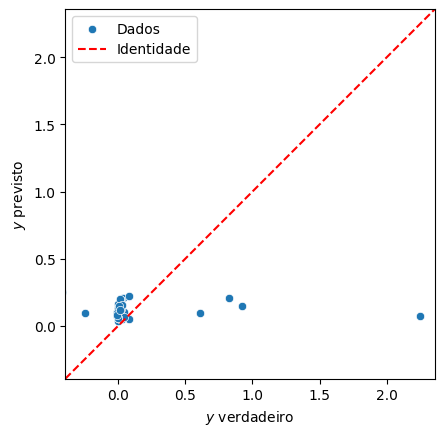

In [19]:
model = create_model_instance(best_trial)
model.fit(X_train, y_train.values.ravel())

true_y = np.asarray(y_test).ravel()
pred_y = np.asarray(model.predict(X_test)).ravel()

RMSE = root_mean_squared_error(true_y, pred_y)

min_val = min(true_y.min(), pred_y.min())
max_val = max(true_y.max(), pred_y.max())

interval = [min_val * 0.95, max_val * 1.05]

eixo = sns.scatterplot(x=true_y, y=pred_y, label="Dados")
eixo.plot(interval, interval, "r--", label="Identidade")

eixo.set(
    xlabel="$y$ verdadeiro",
    ylabel="$y$ previsto",
    xlim=interval,
    ylim=interval,
    aspect="equal",
)
eixo.legend();

print(f"O RMSE calculado é de: {RMSE}")

Aparentemente, o modelo de Floresta Aleatória otimizado conseguiu um RMSE com cerca de 0.033 pontos a menos se comparado ao modelo baseline, apresentando uma métrica levemente pior que o modelo de KNN e de Árvore de Decisão (o que é incomum). Provavelmente precisaríamos de uma buca mais aprofundada de hiperparâmetros e uma quantidade maior de observações para conseguir induzir o modelo adequdamente.

Porém, podemos ver que para os terremotos com log do fator da amplitude próximos de 0 ele consegue prever de uma forma consideravelmente bem.

Vamos ver como ficou a importância dos parâmetros de busca de acordo com o optuna

In [22]:
import optuna.visualization as vis 

vis.plot_param_importances(study_obj)

Pelo gráfico, vemos como a profundidade máxima é o hiperparâmetro mais importantes, seguido do número mínimo de amostras no split e número de árvores da floresta.

## <a id='toc1_3_'></a>[Conclusão](#toc0_)

Sendo assim, nosso modelo de Floresta Aleatória apresentou um RMSE levemente inferior ao obtido pelo modelo baseline. Entretanto, nem todo o espaço de dados foi coberto de forma adequada, e esse algoritmo pode não ser a melhor opção para o problema em questão, apresentando desempenho inferior ao KNN, por exemplo.

<span id="referencias"></span>
## <a id='toc1_4_'></a>[Referências](#toc0_)

1. **CASSAR, Daniel R.** *ATP-203 1.1 - Tratamento de dados com pandas*. Campinas: Ilum Escola de Ciência, 2026.
2. **CASSAR, Daniel R.** *ATP-203 4.0 - Árvore de decisão e floresta aleatória*. Campinas: Ilum Escola de Ciência, 2026.
3. **CASSAR, Daniel R.** *ATP-203 7.1 - Otimização de hiperparâmetros com optuna*. Campinas: Ilum Escola de Ciência, 2026.